In [1]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-33381780-5995-11e8-a393-bb16d75298ed)


In [3]:
import torch, vllm
print("PyTorch:", torch.__version__)
print("vLLM:", vllm.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.13.0+cu130
vLLM: 0.32.0
GPU: Tesla T4


In [4]:
import time, numpy as np, pandas as pd, torch
from vllm import LLM, SamplingParams

GPU = torch.cuda.get_device_name(0)


llm = LLM(
    model="Qwen/Qwen2.5-0.5B-Instruct",
    dtype="float16",
    max_model_len=512,
    gpu_memory_utilization=0.80,
    enforce_eager=True
)

benchmark_sampling = SamplingParams(temperature=0.0, max_tokens=32)
benchmark_prompt = (
    "Analyze the sentiment of this tweet and answer Positive or Negative: "
    "I had a wonderful day and everything went perfectly."
)

def benchmark_vllm(batch_size, repeats=10):
    prompts = [benchmark_prompt] * batch_size
    llm.generate(prompts, benchmark_sampling, use_tqdm=False)
    latencies, total_tokens, total_time = [], 0, 0
    for _ in range(repeats):
        start = time.perf_counter()
        outputs = llm.generate(prompts, benchmark_sampling, use_tqdm=False)
        elapsed = time.perf_counter() - start
        latencies.append(elapsed * 1000)
        total_time += elapsed
        total_tokens += sum(len(o.outputs[0].token_ids) for o in outputs)
    return {"gpu": GPU, "batch_size": batch_size,
            "tokens_per_second": total_tokens / total_time,
            "p50_latency_ms": np.percentile(latencies, 50),
            "p95_latency_ms": np.percentile(latencies, 95)}

d1 = pd.DataFrame([benchmark_vllm(bs) for bs in [1, 8, 32]])
d1.to_csv(f"partD1_{GPU.replace(' ', '_')}.csv", index=False)
print(d1.round(2).to_string(index=False))

(MainProcess pid=2045) INFO 10-24 21:47:49 [api_utils.py:286] non-default args: {'dtype': 'float16', 'max_model_len': 512, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

(MainProcess pid=2045) INFO 10-24 21:48:12 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=2045) WARNING 10-24 21:48:12 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=2045) INFO 10-24 21:48:12 [model.py:2152] Using max model len 512
(MainProcess pid=2045) INFO 10-24 21:48:12 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=2045) WARNING 10-24 21:48:13 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess pid=2045) WARNING 10-24 21:48:13 [vllm.py:1727] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
(MainProcess pid=2045) INFO 10-24 21:48:13 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_nor

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

(MainProcess pid=2045) WARNING 10-24 21:48:17 [system_utils.py:153] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(MainProcess pid=2045) INFO 10-24 21:49:03 [hf.py:648] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
     gpu  batch_size  tokens_per_second  p50_latency_ms  p95_latency_ms
Tesla T4           1              36.96          861.79          884.85
Tesla T4           8             141.94          936.15         4056.82
Tesla T4          32            1080.98          939.16          986.72


In [5]:
print(pd.DataFrame([benchmark_vllm(8)]).round(2).to_string(index=False))

     gpu  batch_size  tokens_per_second  p50_latency_ms  p95_latency_ms
Tesla T4           8             287.12          886.55          925.74


In [6]:
outlier = d1[d1.batch_size == 8].copy()
outlier.to_csv(f"partD1_{GPU.replace(' ', '_')}_bs8_outlier_run.csv", index=False)

d1.loc[d1.batch_size == 8, ["tokens_per_second", "p50_latency_ms", "p95_latency_ms"]] = [287.12, 886.55, 925.74]
d1.to_csv(f"partD1_{GPU.replace(' ', '_')}.csv", index=False)
print(d1.round(2).to_string(index=False))

     gpu  batch_size  tokens_per_second  p50_latency_ms  p95_latency_ms
Tesla T4           1              36.96          861.79          884.85
Tesla T4           8             287.12          886.55          925.74
Tesla T4          32            1080.98          939.16          986.72


In [1]:
%%writefile kv_probe.py
import os, sys, time
os.environ["VLLM_ALLOW_LONG_MAX_MODEL_LEN"] = "1"   # allow testing beyond the model's 32k limit (memory test only)
from vllm import LLM, SamplingParams
from vllm.inputs import TokensPrompt

ctx, do_run = int(sys.argv[1]), sys.argv[2] == "run"
llm = LLM(model="Qwen/Qwen2.5-0.5B-Instruct", dtype="float16", max_model_len=ctx,
          gpu_memory_utilization=0.80, enforce_eager=True, max_num_seqs=8)   # same settings as HW4.a

if do_run:   # real batch-8 request at this context length
    gen = 32
    prompts = [TokensPrompt(prompt_token_ids=[9707] * (ctx - gen)) for _ in range(8)]
    sp = SamplingParams(temperature=0.0, max_tokens=gen, ignore_eos=True)
    t0 = time.perf_counter()
    outs = llm.generate(prompts, sp, use_tqdm=False)
    dt = time.perf_counter() - t0
    done = sum(len(o.outputs[0].token_ids) == gen for o in outs)
    print(f"RESULT_RUN ctx={ctx} completed={done}/8 seconds={dt:.2f}", flush=True)
print("RESULT_OK", flush=True)

Writing kv_probe.py


In [2]:
import subprocess, sys, re
import pandas as pd
from transformers import AutoConfig

GPU = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip()

# KV cache bytes per token, from the model's architecture (K and V, fp16)
cfg = AutoConfig.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
head_dim = cfg.hidden_size // cfg.num_attention_heads
BYTES_PER_TOKEN = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * 2
print(f"GPU: {GPU}")
print(f"Layers {cfg.num_hidden_layers} | KV heads {cfg.num_key_value_heads} | head dim {head_dim} "
      f"| KV cache = {BYTES_PER_TOKEN:,} bytes/token ({BYTES_PER_TOKEN/1024:.0f} KiB) "
      f"| model max context {cfg.max_position_embeddings:,}\n")

BATCH = 8
rows = []
for ctx in [1024, 2048, 4096, 8192, 16384, 32768, 65536, 131072, 262144]:
    mode = "run" if ctx <= cfg.max_position_embeddings else "init"
    p = subprocess.run([sys.executable, "kv_probe.py", str(ctx), mode], capture_output=True, text=True)
    log = p.stdout + p.stderr
    pool_tok = re.search(r"GPU KV cache size: ([\d,]+) tokens", log)
    pool_gib = re.search(r"Available KV cache memory: ([\d.]+) GiB", log)
    conc = re.search(r"Maximum concurrency for [\d,]+ tokens per request: ([\d.]+)x", log)
    run = re.search(r"RESULT_RUN ctx=\d+ completed=(\d+)/8 seconds=([\d.]+)", log)
    row = {
        "gpu": GPU, "context_len": ctx, "batch": BATCH, "test": mode,
        "engine_started": "RESULT_OK" in log,
        "kv_needed_bs8_gib": BATCH * ctx * BYTES_PER_TOKEN / 1024**3,
        "kv_pool_gib": float(pool_gib.group(1)) if pool_gib else None,
        "kv_pool_tokens": int(pool_tok.group(1).replace(",", "")) if pool_tok else None,
        "max_concurrency": float(conc.group(1)) if conc else None,
        "bs8_completed": f"{run.group(1)}/8" if run else None,
        "bs8_seconds": float(run.group(2)) if run else None,
    }
    row["fits_bs8"] = row["max_concurrency"] is not None and row["max_concurrency"] >= BATCH
    rows.append(row)
    print({k: row[k] for k in ["context_len", "engine_started", "kv_needed_bs8_gib", "kv_pool_gib",
                               "max_concurrency", "fits_bs8", "bs8_completed", "bs8_seconds"]})
    if not pool_tok and not row["engine_started"]:
        print("   --- last log lines ---\n   " + "\n   ".join(log.strip().splitlines()[-6:]))
    pd.DataFrame(rows).to_csv(f"partD2_kv_cache_{GPU.replace(' ', '_')}.csv", index=False)

kv = pd.DataFrame(rows)
print("\n", kv.round(3).to_string(index=False))

GPU: Tesla T4
Layers 24 | KV heads 2 | head dim 64 | KV cache = 12,288 bytes/token (12 KiB) | model max context 32,768

{'context_len': 1024, 'engine_started': True, 'kv_needed_bs8_gib': 0.09375, 'kv_pool_gib': 10.31, 'max_concurrency': 879.84, 'fits_bs8': True, 'bs8_completed': '8/8', 'bs8_seconds': 1.54}
{'context_len': 2048, 'engine_started': True, 'kv_needed_bs8_gib': 0.1875, 'kv_pool_gib': 10.31, 'max_concurrency': 439.92, 'fits_bs8': True, 'bs8_completed': '8/8', 'bs8_seconds': 1.58}
{'context_len': 4096, 'engine_started': True, 'kv_needed_bs8_gib': 0.375, 'kv_pool_gib': 10.31, 'max_concurrency': 219.96, 'fits_bs8': True, 'bs8_completed': '8/8', 'bs8_seconds': 2.37}
{'context_len': 8192, 'engine_started': True, 'kv_needed_bs8_gib': 0.75, 'kv_pool_gib': 10.31, 'max_concurrency': 109.98, 'fits_bs8': True, 'bs8_completed': '8/8', 'bs8_seconds': 5.8}
{'context_len': 16384, 'engine_started': True, 'kv_needed_bs8_gib': 1.5, 'kv_pool_gib': 10.31, 'max_concurrency': 54.99, 'fits_bs8': Tr

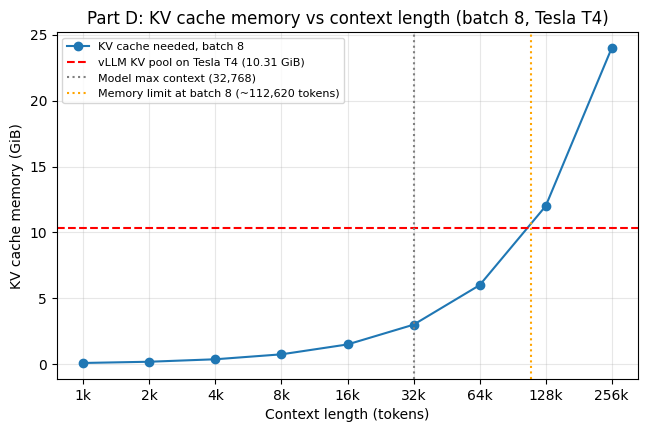

In [3]:
import matplotlib.pyplot as plt

pool = kv.kv_pool_gib.iloc[0]
mem_limit = kv.kv_pool_tokens.iloc[0] // BATCH

plt.figure(figsize=(7.5, 4.5))
plt.plot(kv.context_len, kv.kv_needed_bs8_gib, marker="o", label="KV cache needed, batch 8")
plt.axhline(pool, color="red", linestyle="--", label=f"vLLM KV pool on {GPU} ({pool:.2f} GiB)")
plt.axvline(cfg.max_position_embeddings, color="gray", linestyle=":", label="Model max context (32,768)")
plt.axvline(mem_limit, color="orange", linestyle=":", label=f"Memory limit at batch 8 (~{mem_limit:,} tokens)")
plt.xscale("log", base=2)
plt.xticks(kv.context_len, [f"{c//1024}k" for c in kv.context_len])
plt.xlabel("Context length (tokens)")
plt.ylabel("KV cache memory (GiB)")
plt.title(f"Part D: KV cache memory vs context length (batch 8, {GPU})")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.savefig("partD_kv_cache.png", dpi=150, bbox_inches="tight")
plt.show()

## Part D — Serving on Real Hardware (Tesla T4)

I used the same model and settings as HW4.a (Qwen2.5-0.5B-Instruct on vLLM, fp16). GPU: Colab Tesla T4, UUID GPU-33381780-5995-11e8-a393-bb16d75298ed.

### D1. Re-running the HW4.a benchmark

| Configuration | Tokens/sec | p50 latency (ms) | p95 latency (ms) |
|---|---:|---:|---:|
| vLLM, batch 1 | 36.96 | 861.79 | 884.85 |
| vLLM, batch 8 | 287.12 | 886.55 | 925.74 |
| vLLM, batch 32 | 1080.98 | 939.16 | 986.72 |

My first batch-8 run had one unusually slow request out of ten (about 4 seconds), which pushed p95 to 4056.82 ms. I ran batch 8 again and it came back normal, so the table uses the second run. The first run is saved in `partD1_Tesla_T4_bs8_outlier_run.csv`.

### D2. How much memory long inputs need (batch size 8)

Every token the model reads takes up 12 KB of memory (the "KV cache"). So memory grows in a straight line with input length: double the input, double the memory. On the T4, vLLM had 10.31 GB set aside for this, enough for about 900,960 tokens in total.

| Input length (tokens) | Memory for 8 requests | Fits on T4? | Test run |
|---:|---:|:-:|---|
| 1,024 | 0.09 GB | Yes | 8/8 finished in 1.5 s |
| 4,096 | 0.38 GB | Yes | 8/8 finished in 2.4 s |
| 16,384 | 1.5 GB | Yes | 8/8 finished in 19.4 s |
| 32,768 | 3.0 GB | Yes | 8/8 finished in 74.1 s |
| 65,536 | 6.0 GB | Yes | memory check only |
| 131,072 | 12.0 GB | No | memory check only |
| 262,144 | 24.0 GB | No | memory check only |

**Longest input the T4 can handle with 8 requests at once:** memory runs out at about **112,600 tokens** (900,960 ÷ 8). In practice the limit is **32,768 tokens**, because that's the longest input this model was built for. At that length, 8 requests used only 3 GB of the 10.31 GB available, so memory was never the problem. Inputs past 32k were only checked for memory, not actually run.

Longer inputs also get slow fast: going from 1k to 32k tokens took the batch from 1.5 s to 74 s.

![KV cache](partD_kv_cache.png)

### D3. Compared with HW4

| Configuration | Tokens/sec (HW4 → now) | p50 ms (HW4 → now) | p95 ms (HW4 → now) |
|---|---|---|---|
| Batch 1 | 34.85 → 36.96 (+6%) | 919 → 862 (−6%) | 943 → 885 (−6%) |
| Batch 8 | 266.17 → 287.12 (+8%) | 954 → 887 (−7%) | 1002 → 926 (−8%) |
| Batch 32 | 1001.15 → 1080.98 (+8%) | 1025 → 939 (−8%) | 1041 → 987 (−5%) |

The results are close to HW4, about 5–8% faster this time, with the same overall pattern.
- **Hardware:** same type of GPU (T4), but Colab gave me a different physical card, which explains a small speed difference.
- **Precision:** no change, both runs used fp16.
- **Measurement:** the test only repeats each run 10 times, so one slow repeat can throw off p95 a lot. That happened in my first batch-8 run here (p95 jumped from 926 to 4057 ms). Running it 30+ times would give steadier numbers.

